In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 04b — Model B — DeepLabV3+ with ResNet-50 encoder (multi-scale context CNN)

Part of a **three-model comparison**:

| Notebook | Model | Family |
|---|---|---|
| 04a | U-Net / ResNet-34 | CNN encoder–decoder (baseline) |
| 04b | DeepLabV3+ / ResNet-50 | CNN with multi-scale atrous context |
| 04c | SegFormer / MiT-B2 | Transformer (self-attention) |

**Everything except the network is identical** in all three notebooks (data, splits, augmentation, loss, optimiser, epochs, early stopping) — it all comes from `train_lib.py`. That makes the comparison fair. Compare them afterwards in **05_compare_models.ipynb**.

**Files needed in this folder:** this notebook, `train_lib.py`, `preprocess.py`, and `data/` from notebooks 01–02.
**Output:** `runs/B_deeplabv3plus_resnet50/` → `best.pth`, `last.pth`, `history.csv`, `curves.png`, `val_per_class.csv`, `val_confusion.png`, `val_examples.png`, `metrics.json`, `config.json`.
If the session stops: run all cells again — training resumes from the last finished epoch.

**Why this model**

* **DeepLabV3+** uses **atrous (dilated) convolutions**: convolutions with gaps, so each filter looks at a wider area without shrinking the image further.
  Its **ASPP module** (Atrous Spatial Pyramid Pooling) looks at every pixel at **several scales at once** (dilation rates 12, 24, 36 + whole-patch average).
* A light **decoder** combines this context with low-level detail from the encoder to recover borders.
* **ResNet-50** is a deeper encoder than ResNet-34 (bottleneck blocks), with a similar total parameter count once the U-Net decoder is counted (~25 M), keeping the comparison fair.
* Role in the comparison: tests whether **wider spatial context** helps radar — e.g. telling bare desert from built-up (both bright) by looking at the surroundings, or wetland from grassland by nearby water.
* Possible weakness: output is predicted at 1/4 resolution and upsampled, so thin roads and small fields may blur.

## 1. Setup

In [1]:
import importlib, subprocess, sys
if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "-q",
                           "--no-warn-script-location", "segmentation-models-pytorch"])
sys.path.append(".")
import torch, json
import train_lib as tl
from train_lib import NC, DEV
print("torch", torch.__version__, "| CUDA build", torch.version.cuda)

torch 2.9.1+cu128 | CUDA build 12.8


## 2. Settings

Shared settings are the same in all three notebooks. Only `MODEL_NAME`, `RUN_NAME` and `LR` differ.
To improve this model later, change settings here and **give the run a new `RUN_NAME`** (e.g. add `_v2`), so earlier results are kept.

In [2]:
CFG = dict(
    MODEL_NAME        = "DeepLabV3+ / ResNet-50",
    RUN_NAME          = "B_deeplabv3plus_resnet50",
    DATA              = "data",
    PRETRAINED        = True,          # ImageNet encoder weights (falls back to random if download fails)
    EPOCHS            = 40,
    WARMUP_EPOCHS     = 2,
    BATCH_SIZE        = 16,            # lower to 8 if "CUDA out of memory"
    LR                = 3e-4,
    WEIGHT_DECAY      = 1e-4,
    PATIENCE          = 8,             # early stop if val mIoU does not improve for 8 epochs
    USE_CLASS_WEIGHTS = True,
    USE_DICE          = True,
    NUM_WORKERS       = 2,             # set 0 if you get "shared memory" / worker errors
    SEED              = 42,
)
RUN, DATA, stats, index = tl.setup(CFG)

device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB


## 3. Data (identical for all models)

In [3]:
train_dl, val_dl = tl.make_loaders(CFG, DATA, stats, index)
x, y = next(iter(train_dl))
print("batch x", tuple(x.shape), "| y", tuple(y.shape), "| labels:", sorted(torch.unique(y).tolist()))

loading val:   0%|          | 0/64 [00:00<?, ?it/s]

train patches 700 | val samples 768 (64 patches x 12 months)
batch x (16, 3, 256, 256) | y (16, 256, 256) | labels: [0, 1, 2, 3, 4, 5, 6, 255]


## 4. Model and loss

In [4]:
import segmentation_models_pytorch as smp

def make_model(weights):
    return smp.DeepLabV3Plus(encoder_name="resnet50", encoder_weights=weights,
                             in_channels=3, classes=NC)

try:
    model = make_model("imagenet" if CFG["PRETRAINED"] else None)
    weights_used = "imagenet" if CFG["PRETRAINED"] else "none"
except Exception as e:
    print("Pretrained weights not available -> random start. Reason:", str(e)[:150])
    model, weights_used = make_model(None), "none"
CFG["WEIGHTS_USED"] = weights_used
json.dump(CFG, open(RUN / "config.json", "w"), indent=2)
model = model.to(DEV)
loss_fn = tl.make_loss(CFG, stats)
print(f"{CFG['MODEL_NAME']}: {tl.count_params(model):.1f} M parameters | encoder weights: {weights_used}")
with torch.no_grad():
    print("output shape:", tuple(model(x[:2].to(DEV)).shape), "(must be batch x 7 x 256 x 256)")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

DeepLabV3+ / ResNet-50: 26.7 M parameters | encoder weights: imagenet
output shape: (2, 7, 256, 256) (must be batch x 7 x 256 x 256)


## 5. Sanity check — can the model memorise one batch?
The loss should fall clearly (e.g. from ~3 to below 1). If it doesn't, stop and check the data.

In [5]:
tl.overfit_one_batch(model, loss_fn, train_dl, steps=60, lr=CFG["LR"] * 3)

step  0  loss 2.901
step 10  loss 0.824
step 20  loss 0.587
step 30  loss 0.490
step 40  loss 0.440
step 50  loss 0.404
step 59  loss 0.380


## 6. Training
One line per epoch. `best.pth` = best validation mIoU so far.

In [6]:
history = tl.train(model, CFG, RUN, train_dl, val_dl, loss_fn)

epoch 0:   0%|          | 0/43 [00:00<?, ?it/s]

ep  0 | train 1.900 | val 2.329 | OA 0.453 | mIoU 0.279  *best* | 14s


epoch 1:   0%|          | 0/43 [00:00<?, ?it/s]

ep  1 | train 1.511 | val 2.795 | OA 0.332 | mIoU 0.200 | 12s


epoch 2:   0%|          | 0/43 [00:00<?, ?it/s]

ep  2 | train 1.349 | val 1.943 | OA 0.615 | mIoU 0.367  *best* | 11s


... (52 outputs left out)

epoch 29:   0%|          | 0/43 [00:00<?, ?it/s]

ep 29 | train 0.722 | val 1.528 | OA 0.702 | mIoU 0.474 | 12s


epoch 30:   0%|          | 0/43 [00:00<?, ?it/s]

ep 30 | train 0.726 | val 1.517 | OA 0.712 | mIoU 0.478 | 12s
Early stopping.
Done. Best val mIoU: 0.4931


## 7. Training curves
* **Healthy:** both losses fall, val mIoU rises then flattens.
* **Overfitting:** train loss falls while val loss rises.

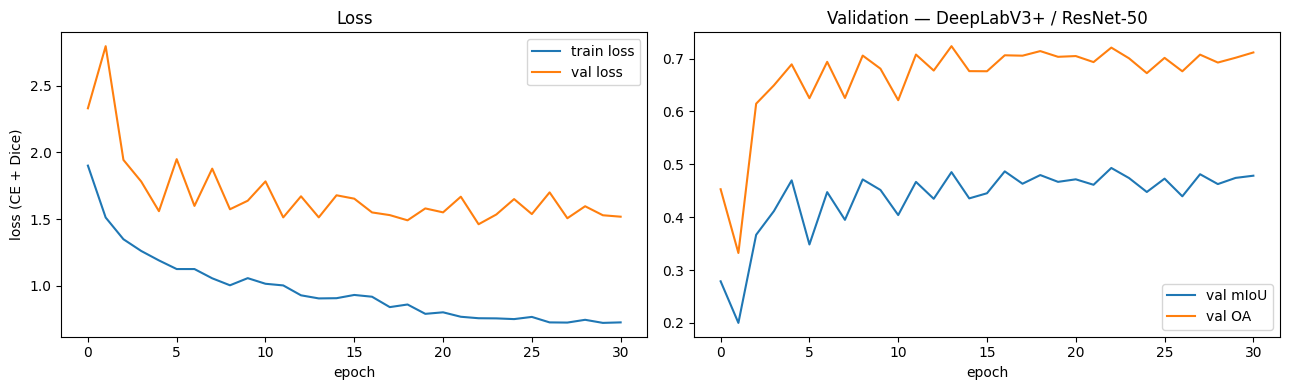

In [7]:
tl.plot_curves(RUN, CFG["MODEL_NAME"])

## 8. Best checkpoint on the validation set
Per-class IoU/F1, confusion matrix and example predictions. **The test set is not used here** — all three models are tested together in notebook 05.

DeepLabV3+ / ResNet-50: val OA 0.721 | val mIoU 0.493 | 26.7 M params | 6.1 min


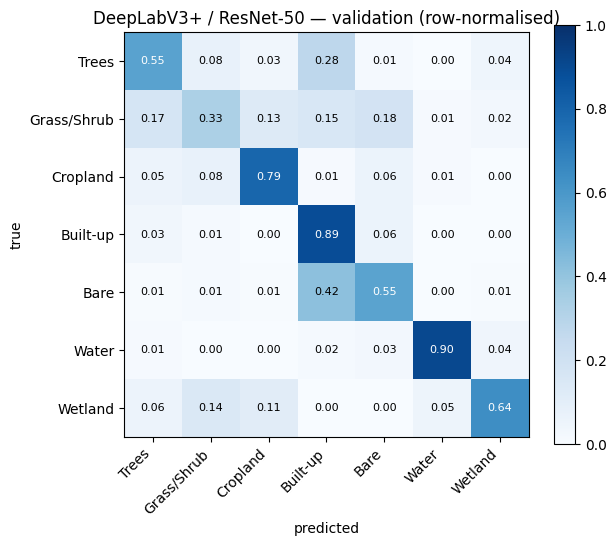

,IoU,F1
Trees,0.438,0.609
Grass/Shrub,0.219,0.359
Cropland,0.491,0.659
Built-up,0.754,0.860
Bare,0.206,0.341
Water,0.747,0.855
Wetland,0.597,0.748
mean,0.493,0.633


In [8]:
res = tl.final_validation(model, CFG, RUN, val_dl)
display(res)

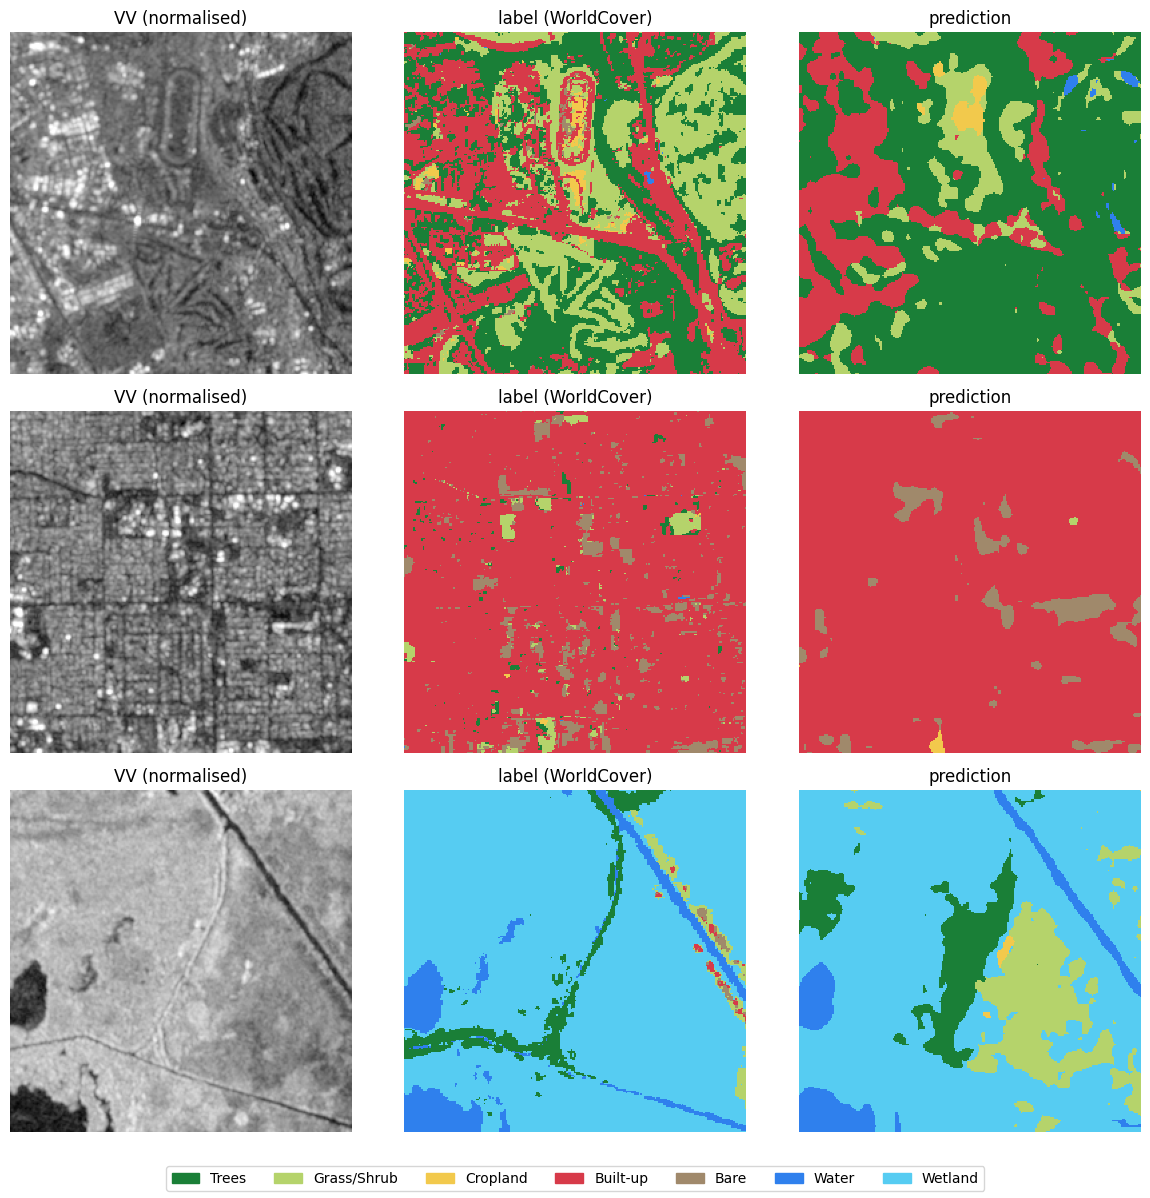

In [9]:
tl.show_predictions(model, val_dl, RUN, n=3, month=6)

## 9. Save results
Zip the run folder and download it, then save this notebook (Ctrl + S) so the outputs stay visible.

In [10]:
import shutil
shutil.make_archive(f"{CFG['RUN_NAME']}_results", "zip", RUN)
print("Download:", f"{CFG['RUN_NAME']}_results.zip")

Download: B_deeplabv3plus_resnet50_results.zip
